# Inferencia

Generación de predicciones de `SalePrice` a partir de los datos crudos de `test.csv`, usando el modelo ganador con su pipeline completo de ingeniería de características. Al final se construye un único pipeline de inferencia que recibe datos crudos y devuelve el precio en dólares.

## 1. Importación de librerías

Se cargan las herramientas para leer el modelo guardado, construir el pipeline de inferencia y calcular métricas.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from matplotlib.ticker import FuncFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from ejercicio_clases.config import MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT, RAW_DATA_DIR

2026-11-03 20:21:44.672 | INFO     | ejercicio_clases.config:<module>:11 - PROJ_ROOT path is: C:\Users\aillu\OneDrive - Empresa Eléctrica de Guatemala, S.A. (EEGSA)\Mis Documentos\Universidad\4. Trimestre\1 - PRODUCT DEVELOPMENT\3. Semana\Ejercicio en Clases\ejercicio_clases


## 2. Parámetros y carga de datos crudos

Se definen las rutas y se cargan `test.csv`, la lista `MODEL_FEATURES` y el modelo ganador.

In [2]:
# Rutas de las fuentes de información (cambiar aquí si los datos se mueven)
TRAIN_FILE = RAW_DATA_DIR / "train.csv"
TEST_FILE = RAW_DATA_DIR / "test.csv"
EJEMPLO_SALIDA_FILE = RAW_DATA_DIR / "sample_submission.csv"
CONFIG_FILE = PROJ_ROOT / "pipeline_config.yaml"
MODELO_GANADOR_FILE = MODELS_DIR / "modelo_ganador.joblib"
PIPELINE_INFERENCIA_FILE = MODELS_DIR / "pipeline_inferencia.joblib"
PREDICCIONES_FILE = PROCESSED_DATA_DIR / "predicciones_test.csv"

TARGET = "SalePrice"
TAMANO_VALIDACION = 0.20
SEMILLA = 42

with open(CONFIG_FILE, encoding="utf-8") as archivo:
    MODEL_FEATURES = yaml.safe_load(archivo)["MODEL_FEATURES"]

df_test = pd.read_csv(TEST_FILE, index_col="Id")
modelo_ganador = joblib.load(MODELO_GANADOR_FILE)

print(f"Test crudo: {df_test.shape} | Features: {len(MODEL_FEATURES)}")
print(f"Pasos del modelo ganador: {[nombre for nombre, _ in modelo_ganador.steps]}")

Test crudo: (1459, 79) | Features: 30
Pasos del modelo ganador: ['fe', 'modelo']


## 3. Predicción sobre los datos crudos de test

El modelo ganador aplica internamente la ingeniería de características y predice en escala logarítmica. Las predicciones se regresan a dólares con `np.expm1`. Ninguna transformación se reajusta con los datos de test.

In [3]:
predicciones_log = modelo_ganador.predict(df_test[MODEL_FEATURES])
predicciones_test = pd.Series(np.expm1(predicciones_log), index=df_test.index, name=TARGET)

predicciones_test.describe().round(0)

count      1459.0
mean     178541.0
std       78190.0
min       52282.0
25%      127718.0
50%      157103.0
75%      205599.0
max      572664.0
Name: SalePrice, dtype: float64

## 4. Almacenamiento de las predicciones

Se guardan las predicciones en `data/processed/predicciones_test.csv`, con las columnas `Id` y `SalePrice` en dólares, y se comprueba que coincidan en estructura con `sample_submission.csv`.

In [4]:
predicciones_test.to_csv(PREDICCIONES_FILE)

ejemplo_salida = pd.read_csv(EJEMPLO_SALIDA_FILE)
archivo_generado = pd.read_csv(PREDICCIONES_FILE)

assert list(archivo_generado.columns) == list(ejemplo_salida.columns)
assert archivo_generado["Id"].equals(ejemplo_salida["Id"])
assert archivo_generado[TARGET].notna().all() and (archivo_generado[TARGET] > 0).all()

print(f"Predicciones guardadas: {archivo_generado.shape[0]} registros")
archivo_generado.head()

Predicciones guardadas: 1459 registros


,Id,SalePrice
0,1461,121476.733158
1,1462,145882.729273
2,1463,180655.702931
3,1464,182430.030690
4,1465,195409.072988


## 5. Construcción del pipeline de inferencia

Se forma un único objeto con el flujo completo:

1. **Selección:** toma las columnas de `MODEL_FEATURES` de los datos crudos.
2. **Ingeniería de características y modelo:** los mismos pasos e hiperparámetros del ganador.
3. **Conversión a dólares:** `TransformedTargetRegressor` aplica `log1p` al target al ajustar y `expm1` al predecir.

`scikit-learn` exige ajustar este objeto para formarlo, así que se ajusta con el mismo conjunto de entrenamiento del ganador (misma división y sin los 2 registros atípicos). Validación y test no participan.

In [5]:
df_train = pd.read_csv(TRAIN_FILE, index_col="Id")

X = df_train.drop(columns=TARGET)
y = df_train[TARGET]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TAMANO_VALIDACION, random_state=SEMILLA
)

ids_atipicos = df_train[(df_train["GrLivArea"] > 4000) & (df_train[TARGET] < 300000)].index
X_train = X_train.drop(ids_atipicos, errors="ignore")
y_train = y_train.drop(ids_atipicos, errors="ignore")

seleccion_variables = ColumnTransformer(
    [("model_features", "passthrough", MODEL_FEATURES)],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

pipeline_inferencia = TransformedTargetRegressor(
    regressor=Pipeline([
        ("seleccion", seleccion_variables),
        ("fe", clone(modelo_ganador.named_steps["fe"])),
        ("modelo", clone(modelo_ganador.named_steps["modelo"])),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
    check_inverse=False,
)

pipeline_inferencia.fit(X_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...907718663)))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",False
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](79,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleType', 'SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,79
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...907718663)))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('seleccion', ...), ('fe', ...), ...]"


## 6. Validación y almacenamiento del pipeline de inferencia

Se comprueba que el pipeline, al recibir datos crudos con todas sus columnas, produzca las mismas predicciones que el modelo ganador en validación y en test, y que el RMSE real coincida con el del torneo. Solo si las comprobaciones pasan, se guarda y se confirma que el archivo cargado da el mismo resultado.

Al final se compara en una misma gráfica la densidad de `SalePrice` real en `train.csv` con la de los precios que el pipeline predice para `test.csv`, para revisar si las predicciones conservan la forma de la distribución real.

RMSE real en validación (pipeline de inferencia): 25,995
Diferencia máxima con el ganador en test: 0.000000 dólares
Guardado en: pipeline_inferencia.joblib


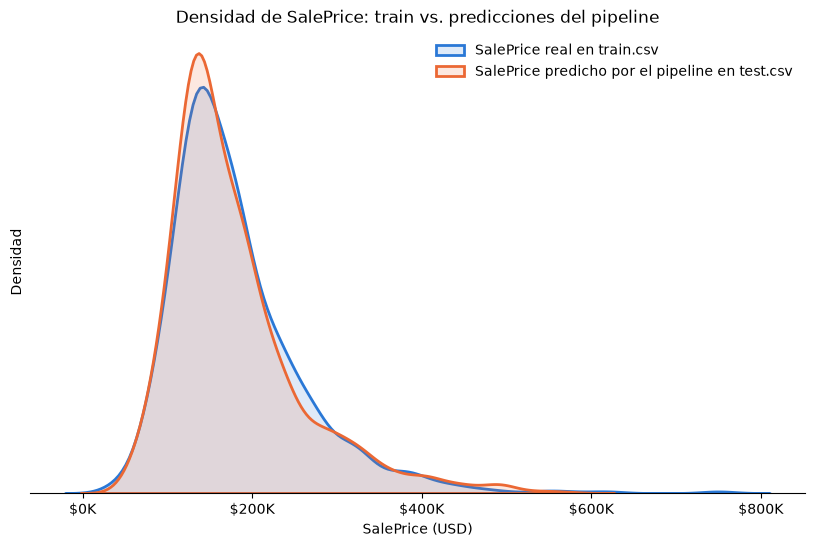

In [6]:
pred_val_pipeline = pipeline_inferencia.predict(X_val)
pred_val_ganador = np.expm1(modelo_ganador.predict(X_val[MODEL_FEATURES]))
pred_test_pipeline = pipeline_inferencia.predict(df_test)

assert np.allclose(pred_val_pipeline, pred_val_ganador)
assert np.allclose(pred_test_pipeline, predicciones_test)

joblib.dump(pipeline_inferencia, PIPELINE_INFERENCIA_FILE)

pipeline_cargado = joblib.load(PIPELINE_INFERENCIA_FILE)
assert np.allclose(pipeline_cargado.predict(df_test), predicciones_test)

print(f"RMSE real en validación (pipeline de inferencia): {root_mean_squared_error(y_val, pred_val_pipeline):,.0f}")
print(f"Diferencia máxima con el ganador en test: {np.abs(pred_test_pipeline - predicciones_test).max():.6f} dólares")
print(f"Guardado en: {PIPELINE_INFERENCIA_FILE.name}")

# Comparación de la distribución real de train contra las predicciones de test
fig, ax = plt.subplots(figsize=(10, 6))
sns.kdeplot(df_train[TARGET], ax=ax, color="#2a78d6", linewidth=2, fill=True, alpha=0.15, label=f"{TARGET} real en train.csv")
sns.kdeplot(pred_test_pipeline, ax=ax, color="#eb6834", linewidth=2, fill=True, alpha=0.15, label=f"{TARGET} predicho por el pipeline en test.csv")
ax.set_title(f"Densidad de {TARGET}: train vs. predicciones del pipeline")
ax.set_xlabel(f"{TARGET} (USD)")
ax.set_ylabel("Densidad")
ax.set_yticks([])
ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"${valor / 1000:,.0f}K"))
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False)
plt.show()